# 06 · Técnicas pythónicas

Los patrones que distinguen a quien escribe Python con soltura: iteradores y generadores, decoradores,
gestores de contexto, herramientas funcionales, anotaciones de tipo, registro (logging), pruebas automáticas y
concurrencia. Cada uno aparece constantemente en las bibliotecas que usarás y en las revisiones de código.

**Aprenderás**
1. Iteradores y generadores, y la caja de herramientas `itertools`
2. Decoradores: medir tiempos, cachear, reintentar
3. Gestores de contexto: limpieza garantizada con `with`
4. Herramientas funcionales: `functools.partial`, `reduce`, `map`/`filter`
5. Anotaciones de tipo que las herramientas pueden comprobar
6. `logging` en lugar de `print`
7. Pruebas con `pytest`
8. Concurrencia: hilos, procesos y `asyncio`, y cuál encaja con cada problema (medido)

## 1. Iteradores, generadores e `itertools`
Todo lo que se puede recorrer con un bucle es un *iterable*; `iter()` da un *iterador* que entrega los
elementos de uno en uno. Los generadores son la forma fácil de escribir iteradores, e `itertools` los combina
sin construir listas en memoria.

In [1]:
import itertools as it

nums = iter([10, 20, 30])
print(next(nums), next(nums), list(nums))

def read_in_batches(items, size):
    batch = []
    for item in items:
        batch.append(item)
        if len(batch) == size:
            yield batch
            batch = []
    if batch:
        yield batch

print(list(read_in_batches(range(7), 3)))
print(list(it.islice(it.count(start=1, step=3), 5)))                 # contador infinito, los 5 primeros
print(list(it.accumulate([1, 2, 3, 4])))                              # total acumulado
print(list(it.chain("ab", "cd")), list(it.product("ab", repeat=2)))
print({k: list(g) for k, g in it.groupby(sorted("mississippi"))})

10 20 [30]
[[0, 1, 2], [3, 4, 5], [6]]
[1, 4, 7, 10, 13]
[1, 3, 6, 10]
['a', 'b', 'c', 'd'] [('a', 'a'), ('a', 'b'), ('b', 'a'), ('b', 'b')]
{'i': ['i', 'i', 'i', 'i'], 'm': ['m'], 'p': ['p', 'p'], 's': ['s', 's', 's', 's']}


## 2. Decoradores
Un decorador es una función que recibe una función y devuelve otra nueva con comportamiento añadido. Poner
`@timer` encima de una definición significa `f = timer(f)`.

In [2]:
import functools, time

def timer(func):
    @functools.wraps(func)                  # conserva el nombre y la documentación originales
    def wrapper(*args, **kwargs):
        t0 = time.perf_counter()
        result = func(*args, **kwargs)
        print(f"{func.__name__} tardó {(time.perf_counter() - t0) * 1000:.1f} ms")
        return result
    return wrapper

def retry(times: int, exceptions=(Exception,)):
    '''Un decorador con argumentos: una función que devuelve un decorador.'''
    def decorate(func):
        @functools.wraps(func)
        def wrapper(*args, **kwargs):
            for attempt in range(1, times + 1):
                try:
                    return func(*args, **kwargs)
                except exceptions as e:
                    print(f"intento {attempt} fallido: {e}")
            raise RuntimeError(f"{func.__name__} falló {times} veces")
        return wrapper
    return decorate

@timer
def slow_sum(n): return sum(range(n))

calls = {"n": 0}
@retry(times=3, exceptions=(ConnectionError,))
def flaky():
    calls["n"] += 1
    if calls["n"] < 3:
        raise ConnectionError("corte de red momentáneo")
    return "ok"

print(slow_sum(5_000_000), flaky())

slow_sum tardó 137.9 ms
intento 1 fallido: corte de red momentáneo
intento 2 fallido: corte de red momentáneo
12499997500000 ok


In [3]:
@functools.lru_cache(maxsize=None)          # memoización de la biblioteca estándar
def fib(n): return n if n < 2 else fib(n - 1) + fib(n - 2)

t0 = time.perf_counter(); print(fib(200)); print(f"{(time.perf_counter() - t0) * 1000:.2f} ms con caché")
print(fib.cache_info())

280571172992510140037611932413038677189525
0.58 ms con caché
CacheInfo(hits=198, misses=201, maxsize=None, currsize=201)


## 3. Gestores de contexto
`with` garantiza que cada preparación vaya acompañada de su limpieza, incluso si se lanza una excepción. Los
archivos, los cerrojos, las transacciones de bases de datos y los ajustes temporales lo usan.

In [4]:
from contextlib import contextmanager, suppress
import os, tempfile

@contextmanager
def working_directory(path):
    old = os.getcwd()
    os.chdir(path)
    try:
        yield path
    finally:
        os.chdir(old)                         # se ejecuta siempre

tmp = tempfile.mkdtemp()
with working_directory(tmp):
    with open("notes.txt", "w") as f:         # el archivo se cierra al terminar el bloque
        f.write("hello")
    print("dentro:", os.getcwd() == os.path.realpath(tmp), os.listdir("."))
print("de vuelta:", os.getcwd() != os.path.realpath(tmp))

with suppress(FileNotFoundError):             # ignora un error concreto y esperado
    os.remove("does-not-exist.txt")

class Timer:
    '''La forma de clase: __enter__ y __exit__.'''
    def __enter__(self):
        self.t0 = time.perf_counter(); return self
    def __exit__(self, exc_type, exc, tb):
        self.elapsed = time.perf_counter() - self.t0
        return False                          # no se tragan las excepciones

with Timer() as t:
    sum(i * i for i in range(1_000_000))
print(f"el bloque tardó {t.elapsed * 1000:.1f} ms")

dentro: True ['notes.txt']
de vuelta: True


el bloque tardó 119.1 ms


## 4. Herramientas funcionales

In [5]:
from functools import partial, reduce
from operator import mul, itemgetter

power = lambda base, exp: base ** exp
square, cube = partial(power, exp=2), partial(power, exp=3)
print(square(7), cube(3))

print(reduce(mul, range(1, 6)))                        # 5! = 120
orders = [("pen", 3), ("book", 12), ("bag", 25)]
print(sorted(orders, key=itemgetter(1), reverse=True))
print(list(filter(lambda o: o[1] > 5, orders)), [name for name, price in orders if price > 5])

49 27
120
[('bag', 25), ('book', 12), ('pen', 3)]
[('book', 12), ('bag', 25)] ['book', 'bag']


## 5. Anotaciones de tipo
Las anotaciones documentan la intención y permiten que las herramientas (`mypy`, `pyright`, tu editor)
detecten errores antes de ejecutar el código.

In [6]:
from typing import TypedDict, Literal, Callable, Iterable, TypeVar

T = TypeVar("T")

class User(TypedDict):
    name: str
    role: Literal["admin", "viewer"]

def first_match(items: Iterable[T], predicate: Callable[[T], bool]) -> T | None:
    return next((i for i in items if predicate(i)), None)

users: list[User] = [{"name": "ana", "role": "viewer"}, {"name": "ben", "role": "admin"}]
print(first_match(users, lambda u: u["role"] == "admin"))
print(first_match.__annotations__)

{'name': 'ben', 'role': 'admin'}
{'items': typing.Iterable[~T], 'predicate': typing.Callable[[~T], bool], 'return': typing.Optional[~T]}


## 6. `logging` en lugar de `print`
`logging` añade niveles, marcas de tiempo y destinos (consola, archivo, un servicio de registros) que puedes
cambiar sin tocar el código.

In [7]:
import logging, io

stream = io.StringIO()
logging.basicConfig(stream=stream, level=logging.INFO, force=True,
                    format="%(asctime)s %(levelname)-7s %(name)s: %(message)s", datefmt="%H:%M:%S")
log = logging.getLogger("pipeline")

log.debug("no se muestra: por debajo del nivel INFO")
log.info("cargadas %d filas", 1200)              # argumentos, no f-strings: solo se formatea si se emite
log.warning("a 3 filas les faltaba el precio")
try:
    1 / 0
except ZeroDivisionError:
    log.exception("la división falló")          # incluye la traza
print(stream.getvalue())

12:10:34 INFO    pipeline: cargadas 1200 filas
12:10:34 WARNING pipeline: a 3 filas les faltaba el precio
12:10:34 ERROR   pipeline: la división falló
Traceback (most recent call last):
  File "/tmp/ipykernel_1035851/2157448921.py", line 12, in <module>
    1 / 0
    ~~^~~
ZeroDivisionError: division by zero



## 7. Pruebas con pytest
Las pruebas son funciones pequeñas cuyo nombre empieza por `test_`; basta con `assert`. `pytest` las encuentra
y las ejecuta. A continuación se escriben en disco un módulo diminuto y sus pruebas, y se ejecutan.

In [8]:
import subprocess, sys, textwrap
proj = tempfile.mkdtemp()
with open(os.path.join(proj, "pricing.py"), "w") as f:
    f.write(textwrap.dedent("""
        def apply_discount(price: float, percent: float) -> float:
            if not 0 <= percent <= 100:
                raise ValueError("percent must be between 0 and 100")
            return round(price * (1 - percent / 100), 2)
    """))
with open(os.path.join(proj, "test_pricing.py"), "w") as f:
    f.write(textwrap.dedent("""
        import pytest
        from pricing import apply_discount

        def test_basic():
            assert apply_discount(100, 20) == 80

        @pytest.mark.parametrize("price, pct, expected", [(50, 0, 50), (50, 100, 0), (19.99, 15, 16.99)])
        def test_many(price, pct, expected):
            assert apply_discount(price, pct) == expected

        def test_rejects_bad_percent():
            with pytest.raises(ValueError):
                apply_discount(10, 120)
    """))
r = subprocess.run([sys.executable, "-m", "pytest", "-q", proj], capture_output=True, text=True, cwd=proj)
print(r.stdout[-400:])

.....                                                                    [100%]
5 passed in 0.02s



## 8. Concurrencia: hilos, procesos, asyncio
Python tiene un *bloqueo global del intérprete* (GIL): en el intérprete estándar solo un hilo ejecuta bytecode
de Python a la vez. La consecuencia:

- Trabajo **limitado por E/S** (esperar a redes, discos, bases de datos): los hilos o `asyncio` solapan las esperas.
- Trabajo **limitado por CPU** (cálculo en Python puro): solo los **procesos** usan varios núcleos (o
  bibliotecas como NumPy que liberan el GIL internamente). Python 3.13 añade una compilación opcional sin GIL
  (free-threaded); todavía es experimental.

Medido a continuación con una tarea de E/S simulada (dormir) y una tarea de CPU (contar primos):

In [9]:
import asyncio
from concurrent.futures import ThreadPoolExecutor, ProcessPoolExecutor

def io_task(_):
    time.sleep(0.2)                          # representa la espera de una petición de red
    return 1

def cpu_task(n):
    return sum(1 for k in range(2, n) if all(k % d for d in range(2, int(k ** 0.5) + 1)))

def timed(label, fn):
    t0 = time.perf_counter(); fn(); dt = time.perf_counter() - t0
    print(f"{label:<34}{dt:6.2f} s"); return dt

JOBS, N = 8, 60_000
results = {}
results["E/S secuencial"] = timed("E/S: secuencial", lambda: [io_task(i) for i in range(JOBS)])
with ThreadPoolExecutor(8) as ex:
    results["E/S hilos"] = timed("E/S: 8 hilos", lambda: list(ex.map(io_task, range(JOBS))))

async def io_async(_):
    await asyncio.sleep(0.2)
async def main():
    await asyncio.gather(*(io_async(i) for i in range(JOBS)))
# los notebooks ya tienen un bucle de eventos en marcha, así que asyncio se ejecuta en un hilo nuevo para esta demo
with ThreadPoolExecutor(1) as ex:
    results["E/S asyncio"] = timed("E/S: asyncio", lambda: ex.submit(asyncio.run, main()).result())

results["CPU secuencial"] = timed("CPU: secuencial", lambda: [cpu_task(N) for _ in range(4)])
with ThreadPoolExecutor(4) as ex:
    results["CPU hilos"] = timed("CPU: 4 hilos", lambda: list(ex.map(cpu_task, [N] * 4)))
# Los procesos de trabajo deben poder encontrar cpu_task. Las funciones definidas en un notebook solo las ven
# con el método de arranque "fork" (Linux, Colab). En un script .py funciona cualquier método.
import multiprocessing as mp
ctx = mp.get_context("fork") if "fork" in mp.get_all_start_methods() else None
if ctx:
    with ProcessPoolExecutor(4, mp_context=ctx) as ex:
        results["CPU procesos"] = timed("CPU: 4 procesos", lambda: list(ex.map(cpu_task, [N] * 4)))
else:
    print("CPU: en esta plataforma los procesos necesitan un archivo .py (sin 'fork'); mira el ejercicio de abajo")

E/S: secuencial                     1.60 s


E/S: 8 hilos                        0.20 s


E/S: asyncio                        0.20 s


CPU: secuencial                     0.65 s


CPU: 4 hilos                        0.93 s


CPU: 4 procesos                     0.30 s


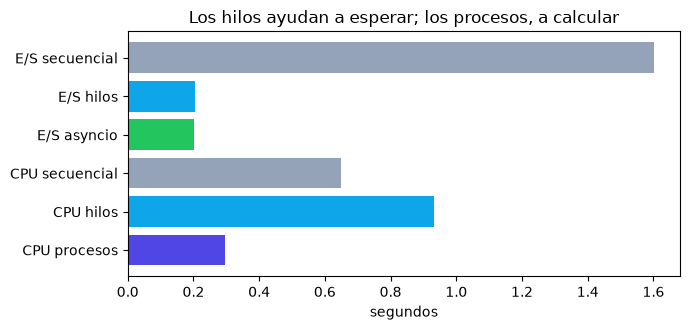

In [10]:
import matplotlib.pyplot as plt
plt.figure(figsize=(7, 3.4))
colors = ["#94a3b8", "#0ea5e9", "#22c55e", "#94a3b8", "#0ea5e9", "#4f46e5"]
plt.barh(list(results), list(results.values()), color=colors); plt.gca().invert_yaxis()
plt.xlabel("segundos"); plt.title("Los hilos ayudan a esperar; los procesos, a calcular"); plt.tight_layout(); plt.show()

Los hilos y asyncio terminan las tareas de E/S en aproximadamente el tiempo de una sola, porque las esperas se
solapan. Para las tareas de CPU los hilos no aceleran nada, a menudo incluso ralentizan un poco (el GIL más el
coste de alternar), mientras que los procesos se ejecutan en núcleos distintos y reducen el tiempo a menos de la
mitad. La ganancia queda por debajo del ideal de 4 veces porque arrancar procesos de trabajo y enviarles el
trabajo tiene un coste, que pesa en tareas tan cortas.

## Ejercicios
1. Escribe un decorador `@count_calls` que registre cuántas veces se ha llamado a una función.
2. Convierte `Timer` en decorador además de gestor de contexto (`contextlib.ContextDecorator`).
3. Añade una prueba para `apply_discount` con un precio negativo y decide qué debería hacer la función.
4. Reescribe la prueba de CPU con NumPy (criba vectorizada) y compárala con cuatro procesos.